# ODEs, Dynamical Systems, and Neural ODEs

**AI Mathematics · 7. Advanced Topics**

Connect differential equations with state evolution, numerical integration, recurrent models, and continuous-depth neural networks.

> The emphasis is on short, reusable examples rather than long projects. Code examples use Python and NumPy unless noted otherwise.

## Learning objectives
- Interpret an ordinary differential equation as a state evolution rule.
- Use Euler’s method for a simple ODE.
- Understand stability and the basic Neural ODE idea.

In [1]:
import numpy as np

## 1. Ordinary differential equations
An ODE defines how a state changes: \(dx/dt=f(t,x)\). Initial conditions determine a particular trajectory when the problem is well-posed. Dynamical systems appear in physical processes, control, recurrent networks, and continuous-time generative models.

In [2]:
import numpy as np

# Exponential decay: dx/dt = -k*x, with exact solution x(t)=x0*exp(-k*t).
k, x0 = 0.7, 1.0
print("exact at t=2:", x0*np.exp(-k*2))

exact at t=2: 0.2465969639416065


## 2. Euler’s method
Forward Euler uses \(x_{t+h}=x_t+h f(t,x_t)\). It is simple but generally first-order accurate and can be unstable when the step size is too large relative to system dynamics.

In [3]:
def euler_decay(k=0.7, x0=1.0, h=0.1, steps=20):
    x = x0
    trajectory = [x]
    for _ in range(steps):
        x = x + h*(-k*x)
        trajectory.append(x)
    return np.array(trajectory)

h = 0.1
trajectory = euler_decay(h=h)
exact = np.exp(-0.7*np.arange(21)*h)
print("Euler final:", trajectory[-1])
print("exact final:", exact[-1])
print("absolute error:", abs(trajectory[-1]-exact[-1]))

Euler final: 0.23423887366259158
exact final: 0.24659696394160643
absolute error: 0.012358090279014855


## 3. Stability and step size
Numerical stability is not the same as accuracy. For the decay equation, Euler gives \(x_{n+1}=(1-hk)x_n\); if \(|1-hk|>1\), errors can grow even though the true solution decays. Smaller steps generally improve Euler accuracy but require more evaluations.

In [4]:
for h in [0.1, 1.0, 2.5, 3.0]:
    vals = euler_decay(k=1.0, h=h, steps=10)
    print("h:", h, "final state:", vals[-1], "max abs:", np.max(np.abs(vals)))

h: 0.1 final state: 0.3486784401 max abs: 1.0
h: 1.0 final state: 0.0 max abs: 1.0
h: 2.5 final state: 57.6650390625 max abs: 57.6650390625
h: 3.0 final state: 1024.0 max abs: 1024.0


## 4. Neural ODEs
A Neural ODE parameterizes the derivative with a neural network, \(dx/dt=f_\theta(t,x)\), and obtains outputs by numerically solving the ODE. This offers continuous-depth dynamics but introduces solver cost, tolerance sensitivity, and challenges in backpropagation through the solution.

In [5]:
# A toy parameterized vector field: dx/dt = theta*x.
def euler_linear(theta, x0, h=0.01, steps=100):
    x = np.asarray(x0, dtype=float)
    for _ in range(steps):
        x = x + h*theta*x
    return x

print("theta=-1:", euler_linear(-1.0, 1.0))
print("theta=0.5:", euler_linear(0.5, 1.0))

theta=-1: 0.3660323412732296
theta=0.5: 1.6466684921165444


## 5. Connection to recurrent networks
A discrete-time recurrent model repeatedly updates a hidden state using inputs and previous state. This resembles discretized dynamical systems. Continuous and discrete models differ in their assumptions, numerical behavior, and computational cost; neither is automatically superior.

### Choosing the right Python tool

- **NumPy** handles arrays, vectorized arithmetic, linear algebra, random sampling, and numerical operations.
- **pandas** is useful for named columns, tabular summaries, and experiment logs.
- **Matplotlib** gives low-level control over vector arrows, geometry, contour plots, and custom figures.
- **Seaborn** is built on Matplotlib and makes statistical plots such as heatmaps, distributions, and grouped comparisons quick to create.

Not every mathematical idea needs all four libraries. The extra examples use each tool where it clarifies the concept. Plots are diagnostic aids: always inspect axes, units, assumptions, and sample size.

## Practical lab: compare an ODE solution with Euler's method

An ordinary differential equation specifies how a state changes over time. For \(dy/dt=-ky\), the exact solution is exponential decay. Euler's method approximates the next state with the current slope, so its accuracy depends on the step size and the dynamics of the system.

23_odes_and_dynamical_systems_neural_odes.ipynb:cell14:21: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


,Euler estimate
step size,
0.05,0.01687
0.2,0.01279
0.5,0.00605


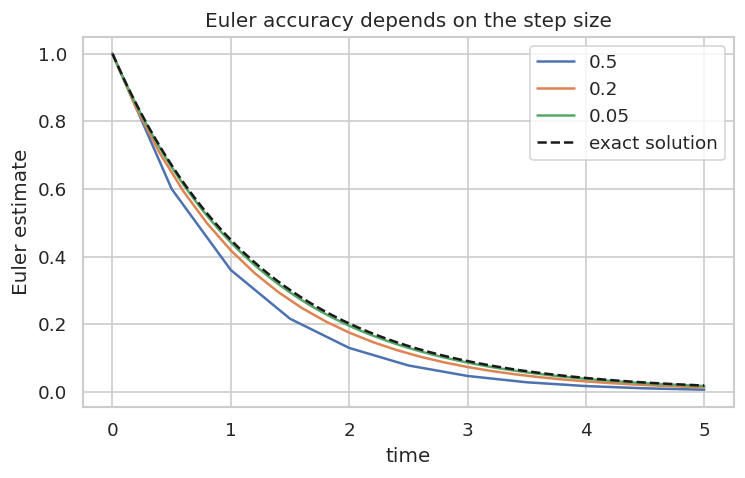

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
sns.set_theme(style="whitegrid")
viz_ode_k, viz_ode_y0, viz_ode_T = 0.8, 1.0, 5.0
viz_ode_df_rows = []
for viz_ode_dt in [0.5, 0.2, 0.05]:
    viz_ode_t = np.arange(0, viz_ode_T+viz_ode_dt/2, viz_ode_dt)
    viz_ode_y = np.empty_like(viz_ode_t); viz_ode_y[0] = viz_ode_y0
    for i in range(len(viz_ode_t)-1):
        viz_ode_y[i+1] = viz_ode_y[i] + viz_ode_dt*(-viz_ode_k*viz_ode_y[i])
    for t, y in zip(viz_ode_t, viz_ode_y):
        viz_ode_df_rows.append({"time": t, "Euler estimate": y, "step size": str(viz_ode_dt)})
viz_ode_df = pd.DataFrame(viz_ode_df_rows)
viz_ode_exact_t = np.linspace(0, viz_ode_T, 300)
fig, ax = plt.subplots(figsize=(7, 4))
sns.lineplot(data=viz_ode_df, x="time", y="Euler estimate", hue="step size", ax=ax)
ax.plot(viz_ode_exact_t, viz_ode_y0*np.exp(-viz_ode_k*viz_ode_exact_t), "k--", label="exact solution")
ax.legend(); ax.set_title("Euler accuracy depends on the step size"); plt.show()
display(viz_ode_df.groupby("step size").tail(1).groupby("step size")["Euler estimate"].last().to_frame().round(5))

### Phase portraits show vector fields

For a two-state system, a vector field shows the direction in which the state moves at each point. A trajectory follows these local directions over time. Phase portraits are helpful for understanding stability, oscillation, and equilibrium points.

23_odes_and_dynamical_systems_neural_odes.ipynb:cell16:9: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


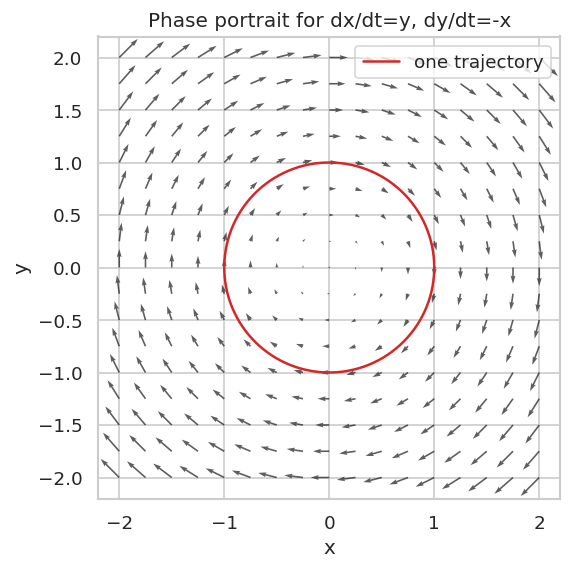

In [7]:
viz_phase_axis = np.linspace(-2, 2, 17)
viz_phase_X, viz_phase_Y = np.meshgrid(viz_phase_axis, viz_phase_axis)
viz_phase_U, viz_phase_V = viz_phase_Y, -viz_phase_X
fig, ax = plt.subplots(figsize=(6, 5))
ax.quiver(viz_phase_X, viz_phase_Y, viz_phase_U, viz_phase_V, alpha=0.7)
viz_phase_t = np.linspace(0, 2*np.pi, 250)
ax.plot(np.cos(viz_phase_t), np.sin(viz_phase_t), color="tab:red", label="one trajectory")
ax.set_aspect("equal", adjustable="box"); ax.set_xlabel("x"); ax.set_ylabel("y"); ax.legend()
ax.set_title("Phase portrait for dx/dt=y, dy/dt=-x"); plt.show()

## Practice exercises
Try each exercise before looking at the suggested solution. These are intentionally small so you can change values and observe how the result changes.

### Exercise 1
Exercise 1: Use Euler’s method for dx/dt=-2x from x0=1 with h=0.1 for five steps.

In [8]:
x, h, k = 1.0, 0.1, 2.0
for _ in range(5): x += h*(-k*x)
print(x)

0.32768


### Exercise 2
Exercise 2: Compare Euler and exact decay at t=1.

In [9]:
h=0.05
trajectory=euler_decay(k=0.7, x0=1.0, h=h, steps=20)
print("Euler:", trajectory[-1], "exact:", np.exp(-0.7))

Euler: 0.49039526349305795 exact: 0.4965853037914095


## Key takeaways
- ODEs specify instantaneous state changes; a solver turns them into trajectories.
- Step size influences stability and accuracy in numerical integration.
- Neural ODEs replace discrete layers with a learned continuous-time vector field and a numerical solver.

**Next step:** Change an input, check the shapes or assumptions, and rerun the relevant cell. That habit is central to mathematical programming.